In [1]:
# EN3150 Assignment 03 - Model A
import argparse, os, time
from types import SimpleNamespace
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)
import pandas as pd

In [2]:
DATA_DIR = "RealWaste"  
IMG_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 50            
SEED = 42

In [3]:
if torch.xpu.is_available():
    DEVICE = torch.device("xpu")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")

Using device: xpu


In [4]:

parser = argparse.ArgumentParser()
parser.add_argument("--opt", choices=["adam", "sgd", "momentum"], default="momentum")
parser.add_argument("--lr", type=float, default=None)
parser.add_argument("--momentum", type=float, default=0.9)
args = SimpleNamespace(opt="adam", lr=None, momentum=0.9)   # opt: "adam" | "sgd" | "momentum"



In [5]:

# class ModelA(nn.Module):
#     def __init__(self, num_classes=5):
#         super().__init__()
#         self.features = nn.Sequential(
#             nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
#             nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
#             nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
#         )
#         self.classifier = nn.Sequential(
#             nn.Flatten(),
#             nn.Linear(64 * 8 * 8, 64), nn.ReLU(inplace=True),
#             nn.Dropout(0.4),
#             nn.Linear(64, num_classes),   # softmax is applied inside the loss
#         )

#     def forward(self, x):
#         return self.classifier(self.features(x))


# def count_params(model):
#     return sum(p.numel() for p in model.parameters() if p.requires_grad)


In [6]:
class ModelA(nn.Module):
    def __init__(self, num_classes=9):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1, bias=False),
                nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(
            block(3, 32), block(32, 64), block(64, 128), block(128, 256),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [7]:
# class DWSeparableConv(nn.Module):
#     """Depthwise 3x3 conv (one filter per channel) + pointwise 1x1 conv (mixes channels)."""
#     def __init__(self, in_ch, out_ch):
#         super().__init__()
#         self.block = nn.Sequential(
#             nn.Conv2d(in_ch, in_ch, 3, padding=1, groups=in_ch, bias=False),  # depthwise
#             nn.BatchNorm2d(in_ch), nn.ReLU(inplace=True),
#             nn.Conv2d(in_ch, out_ch, 1, bias=False),                          # pointwise
#             nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
#         )

#     def forward(self, x):
#         return self.block(x)


# class ModelB(nn.Module):
#     def __init__(self, num_classes=10):
#         super().__init__()
#         self.features = nn.Sequential(
#             # stem: one standard conv (only 3 input channels, so it is cheap)
#             nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True),
#             nn.MaxPool2d(2),                       # 64 -> 32
#             DWSeparableConv(16, 32),  nn.MaxPool2d(2),   # 32 -> 16
#             DWSeparableConv(32, 64),  nn.MaxPool2d(2),   # 16 -> 8
#             DWSeparableConv(64, 128), nn.MaxPool2d(2),   # 8 -> 4
#             DWSeparableConv(128, 256),
#         )
#         self.classifier = nn.Sequential(
#             nn.AdaptiveAvgPool2d(1), nn.Flatten(),       # global average pooling
#             nn.Dropout(0.3),
#             nn.Linear(256, num_classes),                 # softmax is applied inside the loss
#         )

#     def forward(self, x):
#         return self.classifier(self.features(x))


# def count_params(model):
#     return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [8]:
# ---------- Transforms ----------
# Augmentation only for training; val/test get plain resize + normalize
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# ---------- Same images, two views (different transforms) ----------
full_train = datasets.ImageFolder(DATA_DIR, transform=train_tf)
full_eval  = datasets.ImageFolder(DATA_DIR, transform=eval_tf)
classes = full_train.classes
labels  = np.array(full_train.targets)

# ---------- Random stratified split 70 / 15 / 15 ----------
idx = np.arange(len(labels))
train_idx, temp_idx = train_test_split(
    idx, test_size=0.30, stratify=labels, random_state=SEED
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=SEED
)

print(f"Classes: {classes}")
print(f"Train/Val/Test sizes: {len(train_idx)}/{len(val_idx)}/{len(test_idx)}")

# Train uses augmentation; val and test use the plain transform
train_loader = DataLoader(Subset(full_train, train_idx), BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(Subset(full_eval,  val_idx),   BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(Subset(full_eval,  test_idx),  BATCH_SIZE, shuffle=False, num_workers=2)

Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Train/Val/Test sizes: 3326/713/713


In [9]:
# ---------------- Optimizer ----------------
model = ModelA(len(classes)).to(DEVICE)
print(f"Total trainable parameters: {count_params(model):,}")
optimizer = optim.Adam(model.parameters(), lr=1e-3)
# if args.opt == "adam":
#     lr = args.lr or 1e-3
#     optimizer = optim.Adam(model.parameters(), lr=lr)
# elif args.opt == "sgd":
#     lr = args.lr or 1e-2
#     optimizer = optim.SGD(model.parameters(), lr=lr)
# else:
#     lr = args.lr or 1e-2
#     optimizer = optim.SGD(model.parameters(), lr=lr, momentum=args.momentum)
tag = args.opt if args.opt != "momentum" else f"momentum{args.momentum}"
# print(f"Optimizer: {tag}, lr={lr}")

# Class weights for any imbalance between folders
counts = np.bincount(labels[train_idx], minlength=len(classes))
weights = torch.tensor(counts.sum() / (len(classes) * counts), dtype=torch.float32).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=weights)

Total trainable parameters: 391,209


In [ ]:

def run_epoch(loader, train=False):
    model.train(train)
    loss_sum, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return loss_sum / n, correct / n


history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
epoch_times, best_val = [], 0.0
ckpt = f"model_a_{tag}.pth"

for ep in range(1, EPOCHS + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, train=True)
    epoch_times.append(time.time() - t0)
    vl, va = run_epoch(val_loader)
    for k, v in zip(history, (tl, vl, ta, va)):
        history[k].append(v)
    if va > best_val:
        best_val = va
        torch.save(model.state_dict(), ckpt)
    print(f"Epoch {ep:02d}/{EPOCHS} | train loss {tl:.4f} acc {ta:.3f} | "
          f"val loss {vl:.4f} acc {va:.3f} | {epoch_times[-1]:.1f}s")


Epoch 01/50 | train loss 1.9430 acc 0.266 | val loss 1.7607 acc 0.397 | 27.2s
Epoch 02/50 | train loss 1.7035 acc 0.353 | val loss 1.7236 acc 0.403 | 27.7s
Epoch 03/50 | train loss 1.5630 acc 0.403 | val loss 1.6340 acc 0.439 | 25.8s
Epoch 04/50 | train loss 1.4913 acc 0.412 | val loss 1.6051 acc 0.408 | 27.1s
Epoch 05/50 | train loss 1.4200 acc 0.442 | val loss 1.2434 acc 0.540 | 30.5s
Epoch 06/50 | train loss 1.3739 acc 0.464 | val loss 1.2947 acc 0.583 | 28.3s
Epoch 07/50 | train loss 1.3346 acc 0.495 | val loss 1.2196 acc 0.578 | 26.6s
Epoch 08/50 | train loss 1.2952 acc 0.502 | val loss 1.3699 acc 0.495 | 26.4s
Epoch 09/50 | train loss 1.2593 acc 0.518 | val loss 1.1337 acc 0.578 | 19.7s
Epoch 10/50 | train loss 1.2290 acc 0.527 | val loss 1.0848 acc 0.596 | 19.9s
Epoch 11/50 | train loss 1.2028 acc 0.527 | val loss 1.2571 acc 0.579 | 20.4s
Epoch 12/50 | train loss 1.1771 acc 0.554 | val loss 1.0865 acc 0.595 | 19.9s
Epoch 13/50 | train loss 1.1682 acc 0.540 | val loss 1.1134 acc 

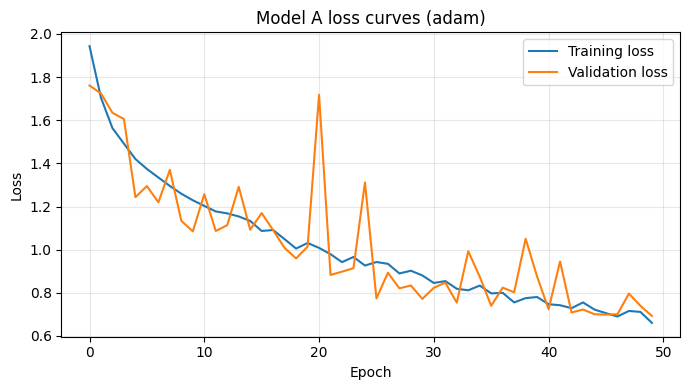

In [11]:

# ---------------- Loss curves ----------------
plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"Model A loss curves ({tag})")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f"model_a_loss_{tag}.png", dpi=150)



===== Model A test results =====
Accuracy : 0.7447
Precision: 0.7635 (macro)
Recall   : 0.7609 (macro)
Confusion matrix:
 [[ 57   2   4   0   0   2   4   0   0]
 [  0  51   0   0   2   0   4   0   5]
 [  0   0  53   1   0   0   9   0   0]
 [  2   3   3  72   8   2  23   5   0]
 [  1   2   2   9  29   2  16  12   2]
 [  4   0   2   4   0  54   8   3   0]
 [  4   1   7   6   2   2 110   6   0]
 [  0   0   0   2   1   2   1  42   0]
 [  0   0   0   1   1   0   0   0  63]]
                     precision    recall  f1-score   support

          Cardboard       0.84      0.83      0.83        69
      Food Organics       0.86      0.82      0.84        62
              Glass       0.75      0.84      0.79        63
              Metal       0.76      0.61      0.68       118
Miscellaneous Trash       0.67      0.39      0.49        75
              Paper       0.84      0.72      0.78        75
            Plastic       0.63      0.80      0.70       138
      Textile Trash       0.62      

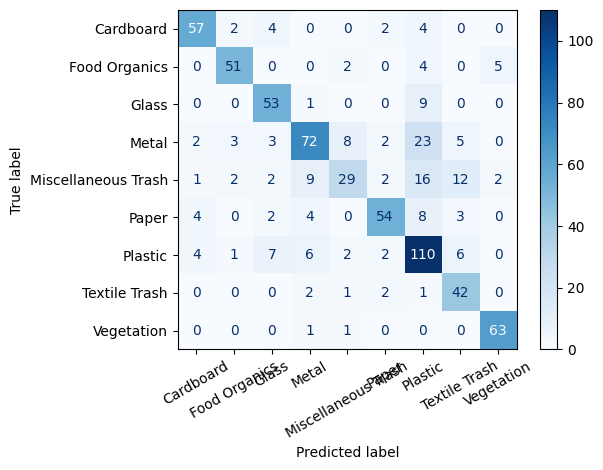

In [12]:

# ---------------- Test evaluation (best-val checkpoint) ----------------
model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        y_pred += model(x.to(DEVICE)).argmax(1).cpu().tolist()
        y_true += y.tolist()

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
cm = confusion_matrix(y_true, y_pred)

print("\n===== Model A test results =====")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f} (macro)")
print(f"Recall   : {rec:.4f} (macro)")
print("Confusion matrix:\n", cm)
print(classification_report(y_true, y_pred, target_names=classes, zero_division=0))

ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap="Blues", xticks_rotation=30)
plt.tight_layout(); plt.savefig(f"model_a_cm_{tag}.png", dpi=150)


In [13]:

# ---------------- Comparison-table numbers ----------------
size_kb = os.path.getsize(ckpt) / 1024
print("\n===== For comparison table =====")
print(f"Total parameters       : {count_params(model):,}")
print(f"Model size on disk     : {size_kb:.1f} KB")
print(f"Avg training time/epoch: {np.mean(epoch_times):.2f} s")
print(f"Test accuracy          : {acc * 100:.2f} %")


===== For comparison table =====
Total parameters       : 391,209
Model size on disk     : 1541.3 KB
Avg training time/epoch: 22.60 s
Test accuracy          : 74.47 %
